# 07 - Single-stock panel, idiosyncratic attention, earnings events, and subsampled realized variance

Notebook 06 tested ETF/article pairs. An ETF dilutes one company's news, so here the target is the **realized variance of the company's own stock**
(SIP 5-minute bars, 2016-2026) for **20 large caps** (list fixed in `src/stocks.py` before any result). Same method: HAR-RV baseline, weekday dummies and the company's own
earnings dummy in both models, attention = two lags of the log-change of the Wikipedia article's views.

## New concepts
| Concept | Meaning |
|---|---|
| **Idiosyncratic attention** | A stock's attention change *minus the average attention change of all 20 stocks* the same day. Removes **market-wide** movements in Wikipedia traffic (holidays, summer lulls, platform-wide shifts) that also move volatility. What is left is *specific* to the company. |
| **Common-factor confound** | When all series share a calendar or market-wide component, a feature can "predict" the target through that shared component, not through the company's own attention. |
| **Earnings reaction day** | The first session after the announcement; a scheduled information shock. |
| **Cluster-robust test** | Earnings days of different stocks fall in the same weeks and share market shocks, so they are not independent. We also test after averaging within calendar weeks. |
| **Signature plot** | Mean realized variance against the sampling interval. If microstructure noise (bid-ask bounce) is present, RV rises at the finest sampling. |
| **Subsampled RV** (Zhang, Mykland & Ait-Sahalia 2005) | Compute RV on the *k* possible offset grids and average them: lower variance and less noise at the same sampling interval. |

In [1]:
import os, sys, warnings
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import model_pipeline as mp, intraday as it, stocks as st
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": .3})
START, END = "2016-01-01", "2026-10-31"
# bars/views/earnings dates are cached in data/ (not committed); re-downloading needs ALPACA_KEY / ALPACA_SECRET

## 1. Sanity check of the earnings dates (yfinance dates are unofficial)

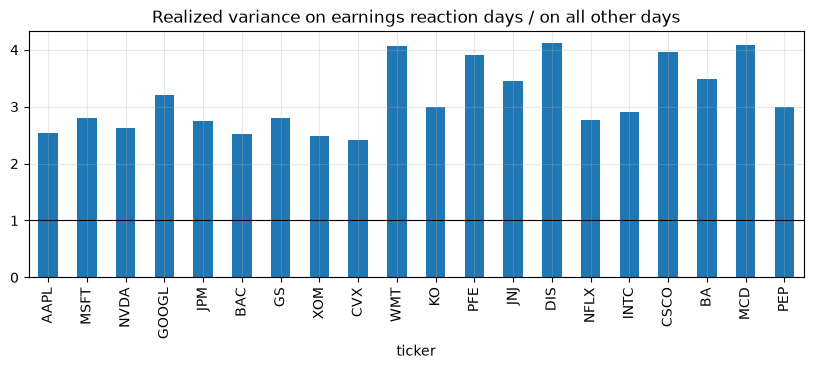

min ratio: 2.42 - every stock has 2.4x-4.1x higher variance on its reaction days: the dates are right.


In [2]:
raw = pd.read_csv("results/stocks_results_raw.csv")
ax = raw.set_index("ticker").earn_rv_ratio.plot.bar(figsize=(10, 3.2), title="Realized variance on earnings reaction days / on all other days")
ax.axhline(1, color="k", lw=.8); plt.show()
print("min ratio:", raw.earn_rv_ratio.min().round(2), "- every stock has 2.4x-4.1x higher variance on its reaction days: the dates are right.")

If the dates were wrong (e.g. shifted by one day) the ratio would be close to 1. It is 2.4-4.1 for all 20 stocks, so the free `yfinance` dates are reliable enough for this use. (We did not use SEC EDGAR: it requires a personal contact e-mail in every request header.)

## 2. Raw attention vs idiosyncratic attention

In [3]:
idio = pd.read_csv("results/stocks_results_idio.csv")
pooled = {t: pd.read_csv(f"results/stocks_pooled_{t}.csv").set_index("test") for t in ("raw", "idio")}
summary = pd.DataFrame({
    "mean OOS R2 gain (%)": [100*raw.r2_oos_gain.mean(), 100*idio.r2_oos_gain.mean()],
    "stocks with negative gain": [(raw.r2_oos_gain < 0).sum(), (idio.r2_oos_gain < 0).sum()],
    "pooled CW p (all days)": [pooled["raw"].loc["pooled_all_days", "p"], pooled["idio"].loc["pooled_all_days", "p"]],
    "NVDA CW p, Holm-adjusted": [raw.set_index("ticker").p_cw_holm["NVDA"], idio.set_index("ticker").p_cw_holm["NVDA"]],
}, index=["raw attention", "idiosyncratic attention"])
summary.round(4)

,mean OOS R2 gain (%),stocks with negative gain,pooled CW p (all days),"NVDA CW p, Holm-adjusted"
raw attention,-0.0114,13,0.0000,0.0127
idiosyncratic attention,-0.1026,19,0.0968,0.0817


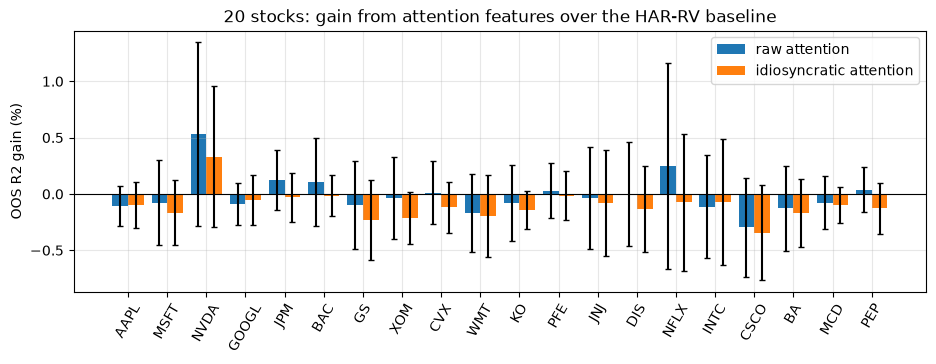

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.4)); x = np.arange(len(raw)); w = .4
ax.bar(x - w/2, 100*raw.r2_oos_gain, w, yerr=196*raw.r2_gain_se, capsize=2, label="raw attention"); ax.bar(x + w/2, 100*idio.r2_oos_gain, w, yerr=196*idio.r2_gain_se, capsize=2, label="idiosyncratic attention")
ax.set_xticks(x); ax.set_xticklabels(raw.ticker, rotation=60); ax.axhline(0, color="k", lw=.8); ax.legend()
ax.set_ylabel("OOS R2 gain (%)"); ax.set_title("20 stocks: gain from attention features over the HAR-RV baseline"); plt.show()

**Reading - the most instructive result of the project.**
- With **raw** attention the pooled Clark-West test is hugely significant ($p\approx2\times10^{-5}$) and Nvidia survives Holm ($p=0.013$): a headline "discovery".
- With **idiosyncratic** attention (market-wide traffic removed) the pooled test drops to $p\approx0.10$, Nvidia to $0.08$ after Holm, and the mean OOS $R^2$ gain becomes **-0.10%, negative for 19 of 20 stocks**.
- So most of the raw "signal" was the **market-wide component of Wikipedia traffic** (holidays, seasonal lulls), which tracks market-wide volatility. It says nothing about attention to a specific company.
- This is the same lesson as the weekday trap in notebooks 05-06, one level up: *any feature that shares a calendar or common factor with the target can fake predictability.*

## 3. Earnings events (20 stocks, ~31 events each)

In [5]:
p = pooled["idio"].round(4)
p

,n,stat,p
test,,,
pooled_all_days,1951,1.2999,0.0968
pooled_earn_reaction_day,627,2.0017,0.0227
pooled_earn_reaction_day_week_clustered,205,1.5201,0.0642
pooled_earn_3day_window,1874,0.5834,0.2798
pooled_earn_3day_window_week_clustered,242,0.7137,0.2377


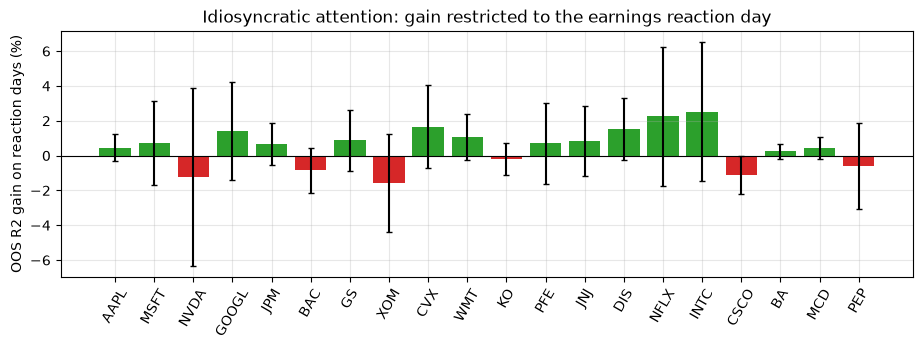

mean gain on reaction days: 0.49 %, positive for 14 of 20


In [6]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(idio.ticker, 100*idio.earn1_r2_gain, yerr=196*idio.earn1_r2_se, capsize=2, color=np.where(idio.earn1_r2_gain > 0, "tab:green", "tab:red"))
ax.axhline(0, color="k", lw=.8); plt.xticks(rotation=60)
ax.set_ylabel("OOS R2 gain on reaction days (%)"); ax.set_title("Idiosyncratic attention: gain restricted to the earnings reaction day"); plt.show()
print("mean gain on reaction days: %.2f %%, positive for %d of 20" % (100*idio.earn1_r2_gain.mean(), (idio.earn1_r2_gain > 0).sum()))

**Reading.** On the earnings reaction day the idiosyncratic attention gain is positive on average ($+0.49\%$ OOS $R^2$, positive for 14 of 20), the only place where attention
seems to help, which is plausible: this is where fresh information arrives. Pooled over 627 stock-events, $p=0.023$ if events were independent, but earnings cluster in the same weeks and share
market shocks: **averaging within calendar weeks (205 clusters) gives $p=0.064$**. The 3-day window gives nothing ($p\approx0.24-0.28$), so the effect, if real, is confined to the reaction day.
We ran several tests in this notebook (all days, 1-day, 3-day, two attention definitions), so $p=0.064$ should not be read as a discovery: **a hint worth a pre-registered follow-up, not a result.**

## 4. Microstructure noise: signature plot and subsampled RV

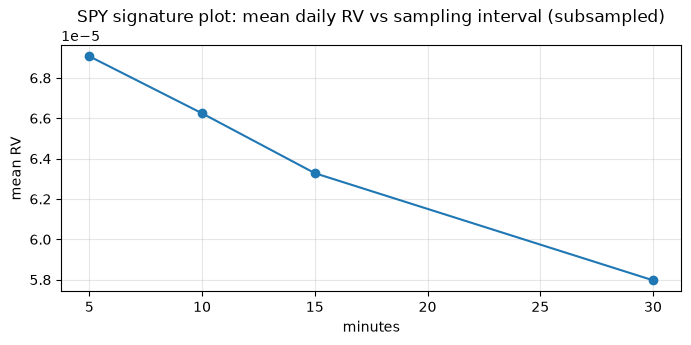

In [7]:
c = it.fetch_bars("SPY", START, END, "5Min", "sip")
sig = {}
for k in (1, 2, 3, 6, 12):
    sig[5*k] = it.daily_rv(c, k).mean()
pd.Series(sig).plot(marker="o", title="SPY signature plot: mean daily RV vs sampling interval (subsampled)", figsize=(8, 3.2))
plt.xlabel("minutes"); plt.ylabel("mean RV"); plt.show()

Mean RV is about 20% higher at 5 minutes than at 60 minutes: some upward bias from microstructure noise (bid-ask bounce, discrete prices). Subsampling averages the RV over
the offset grids, reducing the estimator's variance. Does the conclusion change if we use a **10-minute subsampled RV** (2 offsets) instead of the 5-minute RV?

In [8]:
rows = []
for t, p in mp.PAIRS:
    for sub in (1, 2):
        r, _ = it.evaluate_intraday(t, p, START, END, "ols", True, "5Min", "sip", sub)
        rows.append(dict(ticker=t, page=p, sub=sub, r2_baseline=r["r2_oos_baseline"], r2_gain=r["r2_oos_gain"], p_cw=r["p_cw"]))
from statsmodels.stats.multitest import multipletests
rb = pd.DataFrame(rows)
rb["p_holm"] = rb.groupby("sub").p_cw.transform(lambda x: multipletests(x, method="holm")[1])
rb = rb.pivot(index="ticker", columns="sub", values=["r2_baseline", "r2_gain", "p_cw", "p_holm"]).round(4)
rb.columns = [f"{a} (k={b})" for a, b in rb.columns]
rb

,r2_baseline (k=1),r2_baseline (k=2),r2_gain (k=1),r2_gain (k=2),p_cw (k=1),p_cw (k=2),p_holm (k=1),p_holm (k=2)
ticker,,,,,,,,
GLD,0.4529,0.4265,-0.0019,-0.0013,0.7542,0.8391,1.0000,1.0000
QQQ,0.5957,0.5742,0.0012,0.0015,0.0293,0.0161,0.1466,0.0805
SPY,0.6272,0.6107,0.0024,0.0031,0.0097,0.0069,0.0579,0.0414
XLE,0.7138,0.6819,-0.0019,-0.0009,0.4883,0.3730,1.0000,1.0000
XLF,0.6703,0.6437,-0.0006,-0.0002,0.4707,0.2049,1.0000,0.8195
XLK,0.5873,0.5653,-0.0012,-0.0008,0.6453,0.6038,1.0000,1.0000


With the 10-minute subsampled estimator the baseline $R^2$ is 2-3 points lower (a coarser grid carries less information) and the attention gains stay tiny (at most +0.31%).
Raw p-values move slightly *down* (SPY/Fed 0.0097 -> 0.0069, QQQ 0.029 -> 0.016): SPY/Fed reaches a Holm-adjusted $ppprox0.04$ here versus 0.058 at 5 minutes.
Honest reading: **the estimator does not create or destroy the picture, but SPY/Fed is a borderline hint under both**, and it was one of several specifications we tried (and with the 15-pair panel of notebook 06 its Holm p is 0.145). Not a finding.

## Conclusions
1. **Earnings dates are valid** (reaction-day variance 2.4-4.1x normal for all 20 stocks).
2. **Raw attention looks very significant but it is a common-factor artifact**; with idiosyncratic attention the pooled all-days test is not significant and the mean gain is negative.
3. **Only hint:** on the earnings reaction day idiosyncratic attention helps slightly (+0.49% $R^2$, week-clustered $p=0.064$), within a notebook that ran several tests; it needs a pre-registered replication
   (e.g. on a different set of stocks or the next year's earnings).
4. Subsampling changes the baseline level, not the conclusion; SPY/Fed remains a borderline hint (Holm p 0.04-0.06 on six pairs, 0.145 on the 15-pair panel).
5. Limits: 20 large caps (selection bias toward famous, heavily watched companies), Wikipedia views only, English edition only, close-to-close earnings timing from an unofficial source.